In [1]:
import numpy as np
from matplotlib import pyplot as plt
import json
import scipy.special as special

In [2]:
with open("phase1_results.json") as f:
    results1 = json.load(f)

with open("phase2_linear_results.json") as f:
    results2_linear = json.load(f)

with open("phase2_nonlinear_results.json") as f:
    results2_nonlinear = json.load(f)

In [3]:
n_sim = 500
grid_resolution = 25
copulas = ["gaussian", "clayton", "gumbel"]
Copulas = ["Gaussian", "Clayton", "Gumbel"]

In [4]:
def true_tau1(X):
    x1 = X[:, 0]
    x4 = X[:, 3]

    return special.expit(1.2*x1 - 1.5*x4)

def true_tau2(X):
    x1 = X[:, 0]
    x4 = X[:, 3]

    return special.expit(0.8*np.sin(2*np.pi*x1) + 1.5*(x1 > 0.5) - 1.2*(x4 > 0.7) + 0.6*x4**2)

def true_mu1(X):
    x1 = X[:, 0]
    x3 = X[:, 2]
        
    return np.exp(1.5 + 2*x1 - 3*x3 + np.sin(2*np.pi*x1) + 0.5*x3**2)
    
def true_mu2(X):
    x1 = X[:, 0]
    x2 = X[:, 1]
        
    return np.exp(-1.0 + 1.5*x1 + 2*x2**2 + np.cos(2*np.pi*x2))

np.random.seed(seed=321)
x_pdp = np.random.uniform(0, 1, (5000, 10))

def truth_pdp(
    X,
    feature_index,
    true_theta_fn=None,
    grid=None,
    grid_resolution=50
):
    X = np.asarray(X)
    
    # Grid
    if grid is None:
        xj = X[:, feature_index]
        grid = np.linspace(xj.min(), xj.max(), grid_resolution)

    truth = np.zeros_like(grid) if true_theta_fn else None
    
    for i, val in enumerate(grid):
        X_temp = X.copy()
        X_temp[:, feature_index] = val
        
        # True PDP
        if true_theta_fn:
            theta_true = true_theta_fn(X_temp)
            #if transform:
                #theta_true = transform(theta_true)
            truth[i] = theta_true.mean()
    
    return truth

In [5]:
truth_linear_x1 = truth_pdp(
        x_pdp,
        feature_index=0,
        true_theta_fn=true_tau1,
        grid = np.linspace(0,1,grid_resolution)
    )

truth_linear_x2 = truth_pdp(
        x_pdp,
        feature_index=1,
        true_theta_fn=true_tau1,
        grid = np.linspace(0,1,grid_resolution)
    )

truth_linear_x3 = truth_pdp(
        x_pdp,
        feature_index=2,
        true_theta_fn=true_tau1,
        grid = np.linspace(0,1,grid_resolution)
    )

truth_linear_x4 = truth_pdp(
        x_pdp,
        feature_index=3,
        true_theta_fn=true_tau1,
        grid = np.linspace(0,1,grid_resolution)
    )

truth_nonlinear_x1 = truth_pdp(
        x_pdp,
        feature_index=0,
        true_theta_fn=true_tau2,
        grid = np.linspace(0,1,grid_resolution)
    )

truth_nonlinear_x2 = truth_pdp(
        x_pdp,
        feature_index=1,
        true_theta_fn=true_tau2,
        grid = np.linspace(0,1,grid_resolution)
    )

truth_nonlinear_x3 = truth_pdp(
        x_pdp,
        feature_index=2,
        true_theta_fn=true_tau2,
        grid = np.linspace(0,1,grid_resolution)
    )

truth_nonlinear_x4 = truth_pdp(
        x_pdp,
        feature_index=3,
        true_theta_fn=true_tau2,
        grid = np.linspace(0,1,grid_resolution)
    )

truth_lognormal_x1 = truth_pdp(
        x_pdp,
        feature_index=0,
        true_theta_fn=true_mu1,
        grid = np.linspace(0,1,grid_resolution)
    )

truth_lognormal_x2 = truth_pdp(
        x_pdp,
        feature_index=1,
        true_theta_fn=true_mu1,
        grid = np.linspace(0,1,grid_resolution)
    )

truth_lognormal_x3 = truth_pdp(
        x_pdp,
        feature_index=2,
        true_theta_fn=true_mu1,
        grid = np.linspace(0,1,grid_resolution)
    )

truth_lognormal_x4 = truth_pdp(
        x_pdp,
        feature_index=3,
        true_theta_fn=true_mu1,
        grid = np.linspace(0,1,grid_resolution)
    )

truth_gamma_x1 = truth_pdp(
        x_pdp,
        feature_index=0,
        true_theta_fn=true_mu2,
        grid = np.linspace(0,1,grid_resolution)
    )

truth_gamma_x2 = truth_pdp(
        x_pdp,
        feature_index=1,
        true_theta_fn=true_mu2,
        grid = np.linspace(0,1,grid_resolution)
    )

truth_gamma_x3 = truth_pdp(
        x_pdp,
        feature_index=2,
        true_theta_fn=true_mu2,
        grid = np.linspace(0,1,grid_resolution)
    )

truth_gamma_x4 = truth_pdp(
        x_pdp,
        feature_index=3,
        true_theta_fn=true_mu2,
        grid = np.linspace(0,1,grid_resolution)
    )

In [49]:
#print(results1["linear"]["gaussian"]["feature_importance"])
for copula in copulas:
    # Convert values to NumPy array
    arr = np.array(list(results1["linear"][copula]["feature_importance"]))  # shape = (500, 10)

    # Count selections (> 0) for each feature
    selection_counts = np.sum(arr > 0, axis=0)

    # Compute selection rates
    selection_rates = selection_counts / arr.shape[0]

    # Optional: create feature names
    feature_names = [f"x{i+1}" for i in range(arr.shape[1])]

    # Store in dictionary
    selection_rate_dict = dict(zip(feature_names, selection_rates))

    print(f"{copula}, linear, true")
    print(selection_rate_dict)

for copula in copulas:
    # Convert values to NumPy array
    arr = np.array(list(results1["non-linear"][copula]["feature_importance"]))  # shape = (500, 10)

    # Count selections (> 0) for each feature
    selection_counts = np.sum(arr > 0, axis=0)

    # Compute selection rates
    selection_rates = selection_counts / arr.shape[0]

    # Optional: create feature names
    feature_names = [f"x{i+1}" for i in range(arr.shape[1])]

    # Store in dictionary
    selection_rate_dict = dict(zip(feature_names, selection_rates))

    print(f"{copula}, non-linear, true")
    print(selection_rate_dict)

gaussian, linear, true
{'x1': np.float64(1.0), 'x2': np.float64(0.798), 'x3': np.float64(0.798), 'x4': np.float64(1.0), 'x5': np.float64(0.798), 'x6': np.float64(0.804), 'x7': np.float64(0.822), 'x8': np.float64(0.824), 'x9': np.float64(0.772), 'x10': np.float64(0.814)}
clayton, linear, true
{'x1': np.float64(1.0), 'x2': np.float64(0.074), 'x3': np.float64(0.084), 'x4': np.float64(1.0), 'x5': np.float64(0.068), 'x6': np.float64(0.086), 'x7': np.float64(0.07), 'x8': np.float64(0.064), 'x9': np.float64(0.062), 'x10': np.float64(0.074)}
gumbel, linear, true
{'x1': np.float64(1.0), 'x2': np.float64(0.268), 'x3': np.float64(0.232), 'x4': np.float64(1.0), 'x5': np.float64(0.244), 'x6': np.float64(0.274), 'x7': np.float64(0.248), 'x8': np.float64(0.244), 'x9': np.float64(0.23), 'x10': np.float64(0.256)}
gaussian, non-linear, true
{'x1': np.float64(1.0), 'x2': np.float64(0.86), 'x3': np.float64(0.876), 'x4': np.float64(1.0), 'x5': np.float64(0.882), 'x6': np.float64(0.88), 'x7': np.float64(0.8

In [62]:
def selection_rate_tp(informative_indices, importance_lists):
    """
    Compute the proportion of simulations where ALL informative
    variables were selected (importance > 0).

    Parameters
    ----------
    informative_indices : list of int
        Indices of informative covariates.
        Example: [0, 2, 4]

    importance_lists : list of lists
        Each inner list contains feature importances for one simulation.
        Shape = (n_simulations, n_features)

    Returns
    -------
    float
        Selection rate across simulations.
    """

    arr = np.array(importance_lists)

    # Check if all informative variables were selected (>0)
    correctly_selected = np.all(
        arr[:, informative_indices] > 0,
        axis=1
    )

    # Compute proportion of successful simulations
    return np.mean(correctly_selected)

def selection_rate_fp(informative_indices, importance_lists):
    """
    Compute the proportion of simulations where ANY informative
    variables were selected (importance > 0).

    Parameters
    ----------
    informative_indices : list of int
        Indices of informative covariates.
        Example: [0, 2, 4]

    importance_lists : list of lists
        Each inner list contains feature importances for one simulation.
        Shape = (n_simulations, n_features)

    Returns
    -------
    float
        Selection rate across simulations.
    """

    arr = np.array(importance_lists)

    # Check if all informative variables were selected (>0)
    correctly_selected = np.any(
        arr[:, informative_indices] > 0,
        axis=1
    )

    # Compute proportion of successful simulations
    return np.mean(correctly_selected)

In [63]:
print("true positive")
for copula in copulas:
    print(copula)
    print("linear (true vs pseudo vs lognormal vs gamma):")
    print(selection_rate_tp([0,3], results1["linear"][copula]["feature_importance"]))
    print(selection_rate_tp([0,3], results2_linear[copula]["feature_importance"]))
    print(selection_rate_tp([0,2], results2_linear[copula]["lognormal"]["feature_importance"]))
    print(selection_rate_tp([0,1], results2_linear[copula]["gamma"]["feature_importance"]))
    print("non-linear (true vs pseudo vs lognormal vs gamma):")
    print(selection_rate_tp([0,3], results1["non-linear"][copula]["feature_importance"]))
    print(selection_rate_tp([0,3], results2_nonlinear[copula]["feature_importance"]))
    print(selection_rate_tp([0,2], results2_nonlinear[copula]["lognormal"]["feature_importance"]))
    print(selection_rate_tp([0,1], results2_nonlinear[copula]["gamma"]["feature_importance"]))

true positive
gaussian
linear (true vs pseudo vs lognormal vs gamma):
1.0
1.0
0.988
1.0
non-linear (true vs pseudo vs lognormal vs gamma):
1.0
1.0
0.988
1.0
clayton
linear (true vs pseudo vs lognormal vs gamma):
1.0
1.0
0.974
1.0
non-linear (true vs pseudo vs lognormal vs gamma):
0.988
0.988
0.974
1.0
gumbel
linear (true vs pseudo vs lognormal vs gamma):
1.0
1.0
1.0
1.0
non-linear (true vs pseudo vs lognormal vs gamma):
1.0
0.894
1.0
1.0


In [64]:
print("false positive")
for copula in copulas:
    print(copula)
    print("linear (true vs pseudo vs lognormal vs gamma):")
    print(selection_rate_fp([1,2,4,5,6,7,8,9], results1["linear"][copula]["feature_importance"]))
    print(selection_rate_fp([1,2,4,5,6,7,8,9], results2_linear[copula]["feature_importance"]))
    print(selection_rate_fp([1,3,4,5,6,7,8,9], results2_linear[copula]["lognormal"]["feature_importance"]))
    print(selection_rate_fp([2,3,4,5,6,7,8,9], results2_linear[copula]["gamma"]["feature_importance"]))
    print("non-linear (true vs pseudo vs lognormal vs gamma):")
    print(selection_rate_fp([1,2,4,5,6,7,8,9], results1["non-linear"][copula]["feature_importance"]))
    print(selection_rate_fp([1,2,4,5,6,7,8,9], results2_nonlinear[copula]["feature_importance"]))
    print(selection_rate_fp([1,3,4,5,6,7,8,9], results2_nonlinear[copula]["lognormal"]["feature_importance"]))
    print(selection_rate_fp([2,3,4,5,6,7,8,9], results2_nonlinear[copula]["gamma"]["feature_importance"]))

false positive
gaussian
linear (true vs pseudo vs lognormal vs gamma):
1.0
1.0
0.744
0.996
non-linear (true vs pseudo vs lognormal vs gamma):
1.0
1.0
0.744
0.998
clayton
linear (true vs pseudo vs lognormal vs gamma):
0.456
0.876
0.342
0.998
non-linear (true vs pseudo vs lognormal vs gamma):
0.774
0.884
0.342
0.996
gumbel
linear (true vs pseudo vs lognormal vs gamma):
0.826
1.0
0.998
0.996
non-linear (true vs pseudo vs lognormal vs gamma):
0.998
0.854
0.998
0.992


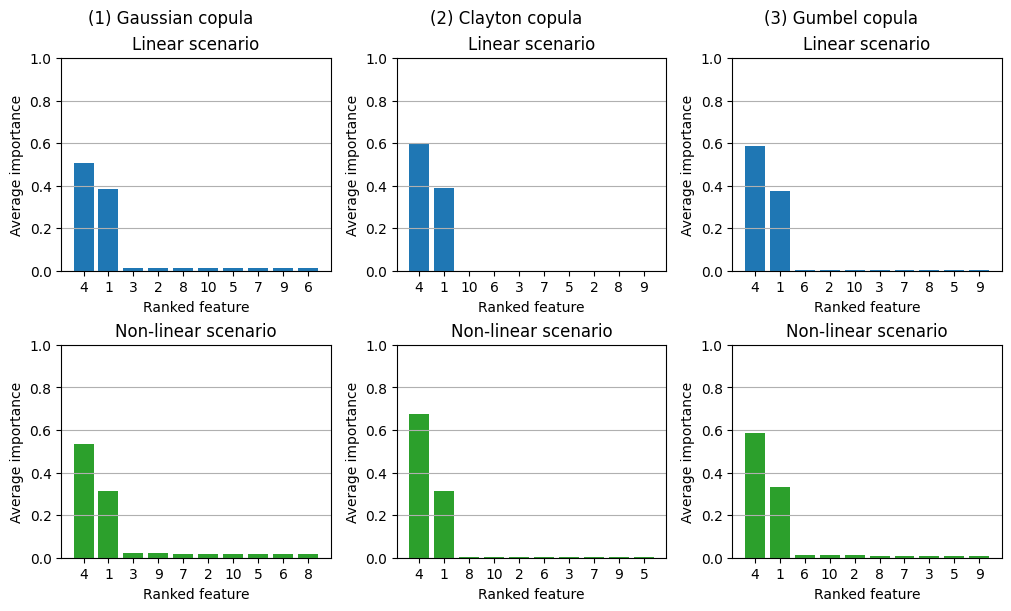

In [8]:
fig = plt.figure(layout='constrained', figsize=(10,6))
subfigs = fig.subfigures(1, 3)

mean_importance_tau_linear = [0]*10
mean_importance_tau_nonlinear = [0]*10

for i in range(3):
    axs = subfigs[i].subplots(2, 1)
    for j in range(n_sim):
        for k in range(len(mean_importance_tau_linear)):
            mean_importance_tau_linear[k] = mean_importance_tau_linear[k] + results1["linear"][copulas[i]]["feature_importance"][j][k]

    for j in range(len(mean_importance_tau_linear)):
        mean_importance_tau_linear[j] = mean_importance_tau_linear[j]/n_sim

    for j in range(n_sim):
        for k in range(len(mean_importance_tau_nonlinear)):
            mean_importance_tau_nonlinear[k] = mean_importance_tau_nonlinear[k] + results1["non-linear"][copulas[i]]["feature_importance"][j][k]

    for j in range(len(mean_importance_tau_nonlinear)):
        mean_importance_tau_nonlinear[j] = mean_importance_tau_nonlinear[j]/n_sim

    # Get indices sorted by value (descending)
    sorted_linear_indices = sorted(range(len(mean_importance_tau_linear)), key=lambda i: mean_importance_tau_linear[i], reverse=True)

    # Convert to 1-based indexing
    ranked_linear_indices = [i + 1 for i in sorted_linear_indices]

    # Corresponding sorted values
    sorted_linear_values = [mean_importance_tau_linear[i] for i in sorted_linear_indices]

    # Plot
    axs[0].bar(range(len(mean_importance_tau_linear)), sorted_linear_values, color="C0")

    # Label x-axis with ranked indices
    axs[0].set_xticks(range(len(mean_importance_tau_linear)), ranked_linear_indices)

    axs[0].set(xlabel="Ranked feature", ylabel="Average importance")
    axs[0].set_title(f"Linear scenario")
    axs[0].grid(axis='y')
    axs[0].set_ylim(0,1)

    # Get indices sorted by value (descending)
    sorted_nonlinear_indices = sorted(range(len(mean_importance_tau_nonlinear)), key=lambda i: mean_importance_tau_nonlinear[i], reverse=True)

    # Convert to 1-based indexing
    ranked_nonlinear_indices = [i + 1 for i in sorted_nonlinear_indices]

    # Corresponding sorted values
    sorted_nonlinear_values = [mean_importance_tau_nonlinear[i] for i in sorted_nonlinear_indices]

    # Plot
    axs[1].bar(range(len(mean_importance_tau_nonlinear)), sorted_nonlinear_values, color="C2")

    # Label x-axis with ranked indices
    axs[1].set_xticks(range(len(mean_importance_tau_nonlinear)), ranked_nonlinear_indices)

    axs[1].set(xlabel="Ranked feature", ylabel="Average importance")
    axs[1].set_title(f"Non-linear scenario")
    axs[1].grid(axis='y')
    axs[1].set_ylim(0,1)
    subfigs[i].suptitle(f"({i+1}) {Copulas[i]} copula", size=12)

#fig.suptitle("Average feature importance of copula XGBoost models trained on true copula observations", size=16)
plt.show()

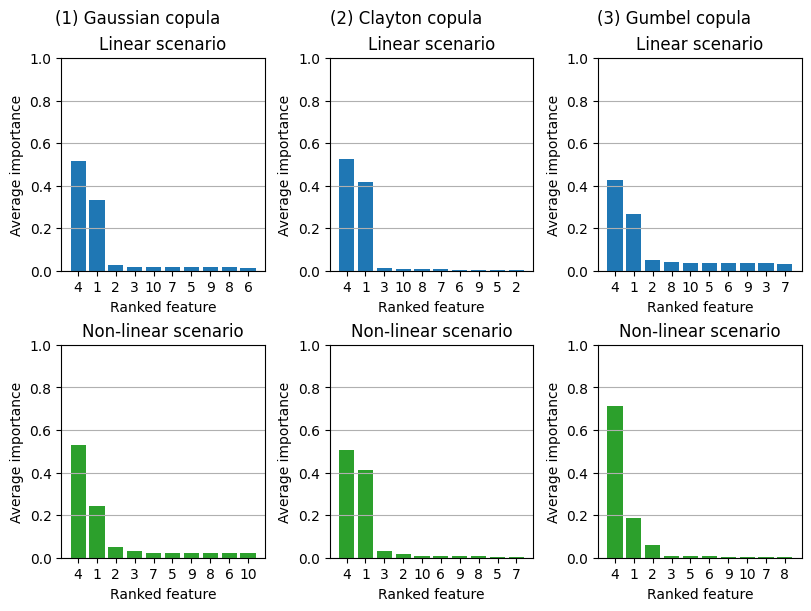

In [9]:
fig = plt.figure(layout='constrained', figsize=(8,6))
subfigs = fig.subfigures(1, 3)

mean_importance_tau_linear = [0]*10
mean_importance_tau_nonlinear = [0]*10

for i in range(3):
    axs = subfigs[i].subplots(2, 1)
    for j in range(n_sim):
        for k in range(len(mean_importance_tau_linear)):
            mean_importance_tau_linear[k] = mean_importance_tau_linear[k] + results2_linear[copulas[i]]["feature_importance"][j][k]

    for j in range(len(mean_importance_tau_linear)):
        mean_importance_tau_linear[j] = mean_importance_tau_linear[j]/n_sim

    for j in range(n_sim):
        for k in range(len(mean_importance_tau_nonlinear)):
            mean_importance_tau_nonlinear[k] = mean_importance_tau_nonlinear[k] + results2_nonlinear[copulas[i]]["feature_importance"][j][k]

    for j in range(len(mean_importance_tau_nonlinear)):
        mean_importance_tau_nonlinear[j] = mean_importance_tau_nonlinear[j]/n_sim

    # Get indices sorted by value (descending)
    sorted_linear_indices = sorted(range(len(mean_importance_tau_linear)), key=lambda i: mean_importance_tau_linear[i], reverse=True)

    # Convert to 1-based indexing
    ranked_linear_indices = [i + 1 for i in sorted_linear_indices]

    # Corresponding sorted values
    sorted_linear_values = [mean_importance_tau_linear[i] for i in sorted_linear_indices]

    # Plot
    axs[0].bar(range(len(mean_importance_tau_linear)), sorted_linear_values, color="C0")

    # Label x-axis with ranked indices
    axs[0].set_xticks(range(len(mean_importance_tau_linear)), ranked_linear_indices)

    axs[0].set(xlabel="Ranked feature", ylabel="Average importance")
    axs[0].set_title(f"Linear scenario")
    axs[0].grid(axis='y')
    axs[0].set_ylim(0,1)

    # Get indices sorted by value (descending)
    sorted_nonlinear_indices = sorted(range(len(mean_importance_tau_nonlinear)), key=lambda i: mean_importance_tau_nonlinear[i], reverse=True)

    # Convert to 1-based indexing
    ranked_nonlinear_indices = [i + 1 for i in sorted_nonlinear_indices]

    # Corresponding sorted values
    sorted_nonlinear_values = [mean_importance_tau_nonlinear[i] for i in sorted_nonlinear_indices]

    # Plot
    axs[1].bar(range(len(mean_importance_tau_nonlinear)), sorted_nonlinear_values, color="C2")

    # Label x-axis with ranked indices
    axs[1].set_xticks(range(len(mean_importance_tau_nonlinear)), ranked_nonlinear_indices)

    axs[1].set(xlabel="Ranked feature", ylabel="Average importance")
    axs[1].set_title(f"Non-linear scenario")
    axs[1].grid(axis='y')
    axs[1].set_ylim(0,1)
    subfigs[i].suptitle(f"({i+1}) {Copulas[i]} copula", size=12)

#fig.suptitle("Average feature importance of copula XGBoost models trained on pseudo-observations", size=16)
plt.show()

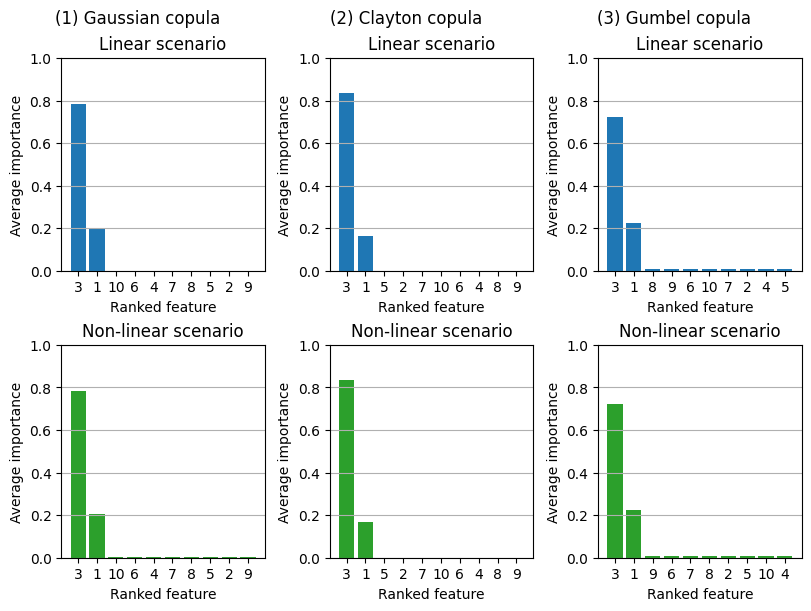

In [10]:
fig = plt.figure(layout='constrained', figsize=(8,6))
subfigs = fig.subfigures(1, 3)

mean_importance_lognormal_linear = [0]*10
mean_importance_lognormal_nonlinear = [0]*10

for i in range(3):
    axs = subfigs[i].subplots(2, 1)
    for j in range(n_sim):
        for k in range(len(mean_importance_lognormal_linear)):
            mean_importance_lognormal_linear[k] = mean_importance_lognormal_linear[k] + results2_linear[copulas[i]]["lognormal"]["feature_importance"][j][k]

    for j in range(len(mean_importance_lognormal_linear)):
        mean_importance_lognormal_linear[j] = mean_importance_lognormal_linear[j]/n_sim

    for j in range(n_sim):
        for k in range(len(mean_importance_lognormal_nonlinear)):
            mean_importance_lognormal_nonlinear[k] = mean_importance_lognormal_nonlinear[k] + results2_nonlinear[copulas[i]]["lognormal"]["feature_importance"][j][k]

    for j in range(len(mean_importance_lognormal_nonlinear)):
        mean_importance_lognormal_nonlinear[j] = mean_importance_lognormal_nonlinear[j]/n_sim

    # Get indices sorted by value (descending)
    sorted_linear_indices = sorted(range(len(mean_importance_lognormal_linear)), key=lambda i: mean_importance_lognormal_linear[i], reverse=True)

    # Convert to 1-based indexing
    ranked_linear_indices = [i + 1 for i in sorted_linear_indices]

    # Corresponding sorted values
    sorted_linear_values = [mean_importance_lognormal_linear[i] for i in sorted_linear_indices]

    # Plot
    axs[0].bar(range(len(mean_importance_lognormal_linear)), sorted_linear_values, color="C0")

    # Label x-axis with ranked indices
    axs[0].set_xticks(range(len(mean_importance_lognormal_linear)), ranked_linear_indices)

    axs[0].set(xlabel="Ranked feature", ylabel="Average importance")
    axs[0].set_title(f"Linear scenario")
    axs[0].grid(axis='y')
    axs[0].set_ylim(0,1)

    # Get indices sorted by value (descending)
    sorted_nonlinear_indices = sorted(range(len(mean_importance_lognormal_nonlinear)), key=lambda i: mean_importance_lognormal_nonlinear[i], reverse=True)

    # Convert to 1-based indexing
    ranked_nonlinear_indices = [i + 1 for i in sorted_nonlinear_indices]

    # Corresponding sorted values
    sorted_nonlinear_values = [mean_importance_lognormal_nonlinear[i] for i in sorted_nonlinear_indices]

    # Plot
    axs[1].bar(range(len(mean_importance_lognormal_nonlinear)), sorted_nonlinear_values, color="C2")

    # Label x-axis with ranked indices
    axs[1].set_xticks(range(len(mean_importance_lognormal_nonlinear)), ranked_nonlinear_indices)

    axs[1].set(xlabel="Ranked feature", ylabel="Average importance")
    axs[1].set_title(f"Non-linear scenario")
    axs[1].grid(axis='y')
    axs[1].set_ylim(0,1)
    subfigs[i].suptitle(f"({i+1}) {Copulas[i]} copula", size=12)

#fig.suptitle("Average feature importance of lognormal marginal XGBoost models", size=16)
plt.show()

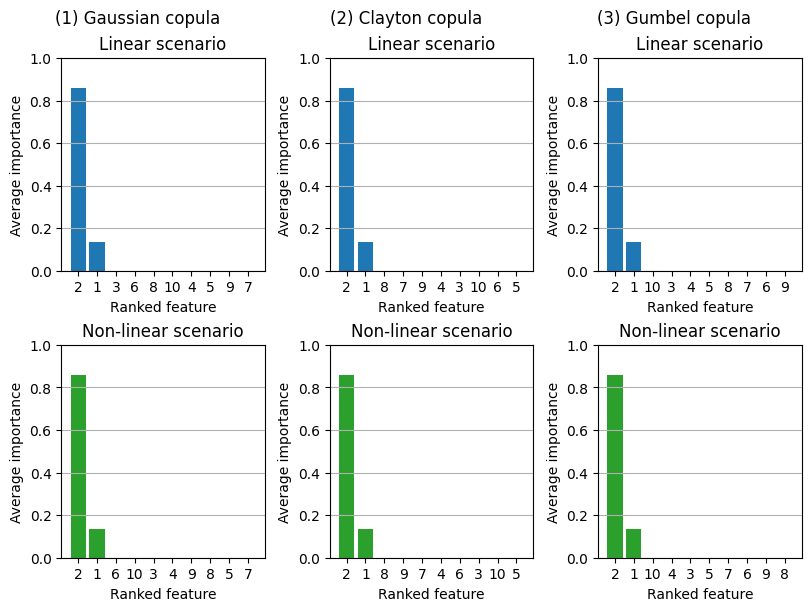

In [11]:
fig = plt.figure(layout='constrained', figsize=(8,6))
subfigs = fig.subfigures(1, 3)

mean_importance_gamma_linear = [0]*10
mean_importance_gamma_nonlinear = [0]*10

for i in range(3):
    axs = subfigs[i].subplots(2, 1)
    for j in range(n_sim):
        for k in range(len(mean_importance_gamma_linear)):
            mean_importance_gamma_linear[k] = mean_importance_gamma_linear[k] + results2_linear[copulas[i]]["gamma"]["feature_importance"][j][k]

    for j in range(len(mean_importance_gamma_linear)):
        mean_importance_gamma_linear[j] = mean_importance_gamma_linear[j]/n_sim

    for j in range(n_sim):
        for k in range(len(mean_importance_gamma_nonlinear)):
            mean_importance_gamma_nonlinear[k] = mean_importance_gamma_nonlinear[k] + results2_nonlinear[copulas[i]]["gamma"]["feature_importance"][j][k]

    for j in range(len(mean_importance_gamma_nonlinear)):
        mean_importance_gamma_nonlinear[j] = mean_importance_gamma_nonlinear[j]/n_sim

    # Get indices sorted by value (descending)
    sorted_linear_indices = sorted(range(len(mean_importance_gamma_linear)), key=lambda i: mean_importance_gamma_linear[i], reverse=True)

    # Convert to 1-based indexing
    ranked_linear_indices = [i + 1 for i in sorted_linear_indices]

    # Corresponding sorted values
    sorted_linear_values = [mean_importance_gamma_linear[i] for i in sorted_linear_indices]

    # Plot
    axs[0].bar(range(len(mean_importance_gamma_linear)), sorted_linear_values, color="C0")

    # Label x-axis with ranked indices
    axs[0].set_xticks(range(len(mean_importance_gamma_linear)), ranked_linear_indices)

    axs[0].set(xlabel="Ranked feature", ylabel="Average importance")
    axs[0].set_title(f"Linear scenario")
    axs[0].grid(axis='y')
    axs[0].set_ylim(0,1)

    # Get indices sorted by value (descending)
    sorted_nonlinear_indices = sorted(range(len(mean_importance_gamma_nonlinear)), key=lambda i: mean_importance_gamma_nonlinear[i], reverse=True)

    # Convert to 1-based indexing
    ranked_nonlinear_indices = [i + 1 for i in sorted_nonlinear_indices]

    # Corresponding sorted values
    sorted_nonlinear_values = [mean_importance_gamma_nonlinear[i] for i in sorted_nonlinear_indices]

    # Plot
    axs[1].bar(range(len(mean_importance_gamma_nonlinear)), sorted_nonlinear_values, color="C2")

    # Label x-axis with ranked indices
    axs[1].set_xticks(range(len(mean_importance_gamma_nonlinear)), ranked_nonlinear_indices)

    axs[1].set(xlabel="Ranked feature", ylabel="Average importance")
    axs[1].set_title(f"Non-linear scenario")
    axs[1].grid(axis='y')
    axs[1].set_ylim(0,1)
    subfigs[i].suptitle(f"({i+1}) {Copulas[i]} copula", size=12)

#fig.suptitle("Average feature importance of gamma marginal XGBoost models", size=16)
plt.show()

In [10]:
copula = "gumbel"
Copula = "Gumbel"

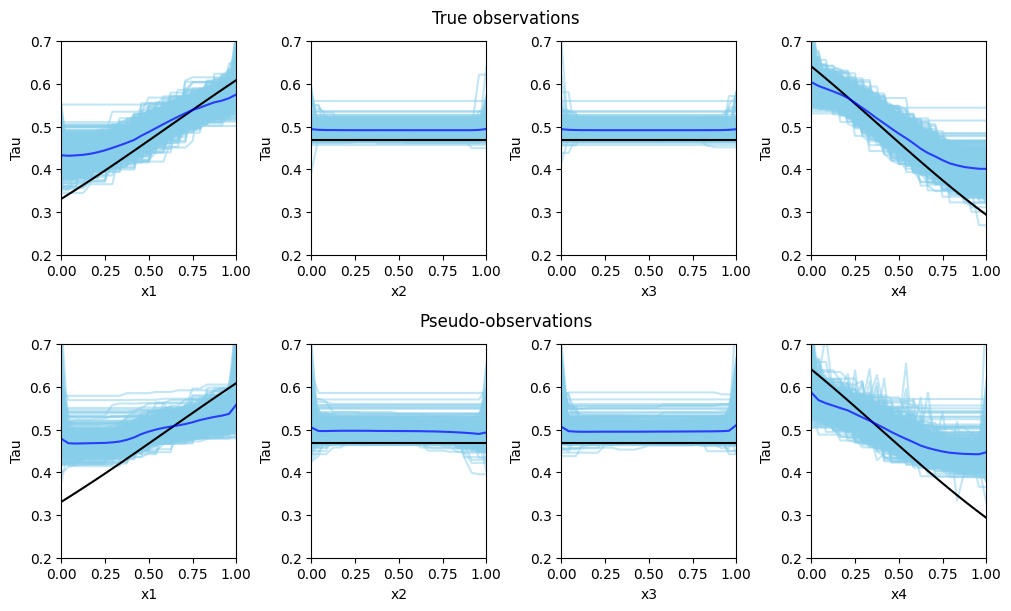

In [13]:
fig = plt.figure(layout='constrained', figsize=(10,6))
subfigs = fig.subfigures(2, 1)

mean_pdp_true_linear_x1 = [0]*grid_resolution
mean_pdp_true_linear_x2 = [0]*grid_resolution
mean_pdp_true_linear_x3 = [0]*grid_resolution
mean_pdp_true_linear_x4 = [0]*grid_resolution

mean_pdp_pseudo_linear_x1 = [0]*grid_resolution
mean_pdp_pseudo_linear_x2 = [0]*grid_resolution
mean_pdp_pseudo_linear_x3 = [0]*grid_resolution
mean_pdp_pseudo_linear_x4 = [0]*grid_resolution

axsTrue = subfigs[0].subplots(1, 4)
axsPseudo = subfigs[1].subplots(1, 4)

for i in range(n_sim):
    axsTrue[0].plot(np.linspace(0,1, grid_resolution), results1["linear"][copula]["pdp"]["x1"][i], alpha = 0.5, color="skyblue")
    for j in range(grid_resolution):
        mean_pdp_true_linear_x1[j] = mean_pdp_true_linear_x1[j] +  results1["linear"][copula]["pdp"]["x1"][i][j]

for i in range(len(mean_pdp_true_linear_x1)):
    mean_pdp_true_linear_x1[i] = mean_pdp_true_linear_x1[i]/n_sim
    
axsTrue[0].plot(np.linspace(0,1, grid_resolution), truth_linear_x1, alpha = 1, color="black")
axsTrue[0].plot(np.linspace(0,1, grid_resolution), mean_pdp_true_linear_x1, alpha=0.7, color="blue")
axsTrue[0].set_ylim(0.2,0.7)
axsTrue[0].set_xlim(0,1)

for i in range(n_sim):
    axsTrue[1].plot(np.linspace(0,1, grid_resolution), results1["linear"][copula]["pdp"]["x2"][i], alpha = 0.5, color="skyblue")
    for j in range(grid_resolution):
        mean_pdp_true_linear_x2[j] = mean_pdp_true_linear_x2[j] +  results1["linear"][copula]["pdp"]["x2"][i][j]

for i in range(len(mean_pdp_true_linear_x2)):
    mean_pdp_true_linear_x2[i] = mean_pdp_true_linear_x2[i]/n_sim
    
axsTrue[1].plot(np.linspace(0,1, grid_resolution), truth_linear_x2, alpha = 1, color="black")
axsTrue[1].plot(np.linspace(0,1, grid_resolution), mean_pdp_true_linear_x2, alpha=0.7, color="blue")
axsTrue[1].set_ylim(0.2,0.7)
axsTrue[1].set_xlim(0,1)

for i in range(n_sim):
    axsTrue[2].plot(np.linspace(0,1, grid_resolution), results1["linear"][copula]["pdp"]["x3"][i], alpha = 0.5, color="skyblue")
    for j in range(grid_resolution):
        mean_pdp_true_linear_x3[j] = mean_pdp_true_linear_x3[j] +  results1["linear"][copula]["pdp"]["x3"][i][j]

for i in range(len(mean_pdp_true_linear_x3)):
    mean_pdp_true_linear_x3[i] = mean_pdp_true_linear_x3[i]/n_sim
    
axsTrue[2].plot(np.linspace(0,1, grid_resolution), truth_linear_x3, alpha = 1, color="black")
axsTrue[2].plot(np.linspace(0,1, grid_resolution), mean_pdp_true_linear_x3, alpha=0.7, color="blue")
axsTrue[2].set_ylim(0.2,0.7)
axsTrue[2].set_xlim(0,1)

for i in range(n_sim):
    axsTrue[3].plot(np.linspace(0,1, grid_resolution), results1["linear"][copula]["pdp"]["x4"][i], alpha = 0.5, color="skyblue")
    for j in range(grid_resolution):
        mean_pdp_true_linear_x4[j] = mean_pdp_true_linear_x4[j] +  results1["linear"][copula]["pdp"]["x4"][i][j]

for i in range(len(mean_pdp_true_linear_x4)):
    mean_pdp_true_linear_x4[i] = mean_pdp_true_linear_x4[i]/n_sim
    
axsTrue[3].plot(np.linspace(0,1, grid_resolution), truth_linear_x4, alpha = 1, color="black")
axsTrue[3].plot(np.linspace(0,1, grid_resolution), mean_pdp_true_linear_x4, alpha=0.7, color="blue")
axsTrue[3].set_ylim(0.2,0.7)
axsTrue[3].set_xlim(0,1)

axsTrue[0].set(xlabel='x1', ylabel = 'Tau')
axsTrue[1].set(xlabel='x2', ylabel = 'Tau')
axsTrue[2].set(xlabel='x3', ylabel = 'Tau')
axsTrue[3].set(xlabel='x4', ylabel = 'Tau')

subfigs[0].suptitle("True observations")

for i in range(n_sim):
    axsPseudo[0].plot(np.linspace(0,1, grid_resolution), results2_linear[copula]["pdp"]["x1"][i], alpha = 0.5, color="skyblue")
    for j in range(grid_resolution):
        mean_pdp_pseudo_linear_x1[j] = mean_pdp_pseudo_linear_x1[j] +  results2_linear[copula]["pdp"]["x1"][i][j]

for i in range(len(mean_pdp_pseudo_linear_x1)):
    mean_pdp_pseudo_linear_x1[i] = mean_pdp_pseudo_linear_x1[i]/n_sim
    
axsPseudo[0].plot(np.linspace(0,1, grid_resolution), truth_linear_x1, alpha = 1, color="black")
axsPseudo[0].plot(np.linspace(0,1, grid_resolution), mean_pdp_pseudo_linear_x1, alpha=0.7, color="blue")
axsPseudo[0].set_ylim(0.2,0.7)
axsPseudo[0].set_xlim(0,1)

for i in range(n_sim):
    axsPseudo[1].plot(np.linspace(0,1, grid_resolution), results2_linear[copula]["pdp"]["x2"][i], alpha = 0.5, color="skyblue")
    for j in range(grid_resolution):
        mean_pdp_pseudo_linear_x2[j] = mean_pdp_pseudo_linear_x2[j] +  results2_linear[copula]["pdp"]["x2"][i][j]

for i in range(len(mean_pdp_pseudo_linear_x2)):
    mean_pdp_pseudo_linear_x2[i] = mean_pdp_pseudo_linear_x2[i]/n_sim
    
axsPseudo[1].plot(np.linspace(0,1, grid_resolution), truth_linear_x2, alpha = 1, color="black")
axsPseudo[1].plot(np.linspace(0,1, grid_resolution), mean_pdp_pseudo_linear_x2, alpha=0.7, color="blue")
axsPseudo[1].set_ylim(0.2,0.7)
axsPseudo[1].set_xlim(0,1)

for i in range(n_sim):
    axsPseudo[2].plot(np.linspace(0,1, grid_resolution), results2_linear[copula]["pdp"]["x3"][i], alpha = 0.5, color="skyblue")
    for j in range(grid_resolution):
        mean_pdp_pseudo_linear_x3[j] = mean_pdp_pseudo_linear_x3[j] +  results2_linear[copula]["pdp"]["x3"][i][j]

for i in range(len(mean_pdp_pseudo_linear_x3)):
    mean_pdp_pseudo_linear_x3[i] = mean_pdp_pseudo_linear_x3[i]/n_sim
    
axsPseudo[2].plot(np.linspace(0,1, grid_resolution), truth_linear_x3, alpha = 1, color="black")
axsPseudo[2].plot(np.linspace(0,1, grid_resolution), mean_pdp_pseudo_linear_x3, alpha=0.7, color="blue")
axsPseudo[2].set_ylim(0.2,0.7)
axsPseudo[2].set_xlim(0,1)

for i in range(n_sim):
    axsPseudo[3].plot(np.linspace(0,1, grid_resolution), results2_linear[copula]["pdp"]["x4"][i], alpha = 0.5, color="skyblue")
    for j in range(grid_resolution):
        mean_pdp_pseudo_linear_x4[j] = mean_pdp_pseudo_linear_x4[j] +  results2_linear[copula]["pdp"]["x4"][i][j]

for i in range(len(mean_pdp_pseudo_linear_x4)):
    mean_pdp_pseudo_linear_x4[i] = mean_pdp_pseudo_linear_x4[i]/n_sim
    
axsPseudo[3].plot(np.linspace(0,1, grid_resolution), truth_linear_x4, alpha = 1, color="black")
axsPseudo[3].plot(np.linspace(0,1, grid_resolution), mean_pdp_pseudo_linear_x4, alpha=0.7, color="blue")
axsPseudo[3].set_ylim(0.2,0.7)
axsPseudo[3].set_xlim(0,1)

axsPseudo[0].set(xlabel='x1', ylabel = 'Tau')
axsPseudo[1].set(xlabel='x2', ylabel = 'Tau')
axsPseudo[2].set(xlabel='x3', ylabel = 'Tau')
axsPseudo[3].set(xlabel='x4', ylabel = 'Tau')

subfigs[1].suptitle("Pseudo-observations")

#for ax in axs.flat:
    #ax.set(ylabel='Tau')
    #ax.label_outer()

#fig.suptitle(f"Estimated covariate effect for {Copula} copula XGBoost model (Linear dependence) ")

plt.show()

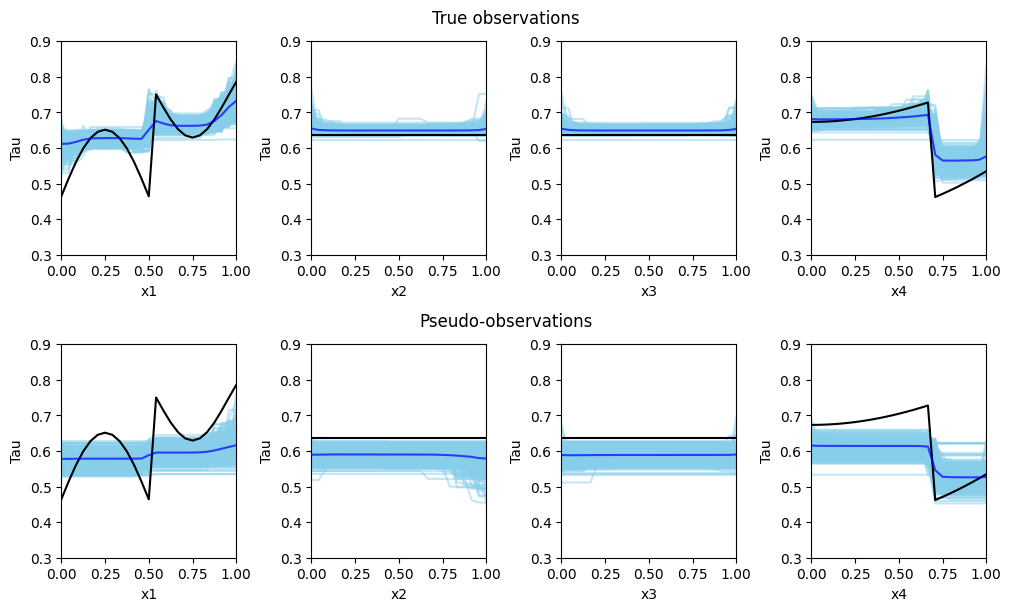

In [11]:
fig = plt.figure(layout='constrained', figsize=(10,6))
subfigs = fig.subfigures(2, 1)

mean_pdp_true_nonlinear_x1 = [0]*grid_resolution
mean_pdp_true_nonlinear_x2 = [0]*grid_resolution
mean_pdp_true_nonlinear_x3 = [0]*grid_resolution
mean_pdp_true_nonlinear_x4 = [0]*grid_resolution

mean_pdp_pseudo_nonlinear_x1 = [0]*grid_resolution
mean_pdp_pseudo_nonlinear_x2 = [0]*grid_resolution
mean_pdp_pseudo_nonlinear_x3 = [0]*grid_resolution
mean_pdp_pseudo_nonlinear_x4 = [0]*grid_resolution

axsTrue = subfigs[0].subplots(1, 4)
axsPseudo = subfigs[1].subplots(1, 4)

for i in range(n_sim):
    axsTrue[0].plot(np.linspace(0,1, grid_resolution), results1["non-linear"][copula]["pdp"]["x1"][i], alpha = 0.5, color="skyblue")
    for j in range(grid_resolution):
        mean_pdp_true_nonlinear_x1[j] = mean_pdp_true_nonlinear_x1[j] +  results1["non-linear"][copula]["pdp"]["x1"][i][j]

for i in range(len(mean_pdp_true_nonlinear_x1)):
    mean_pdp_true_nonlinear_x1[i] = mean_pdp_true_nonlinear_x1[i]/n_sim
    
axsTrue[0].plot(np.linspace(0,1, grid_resolution), truth_nonlinear_x1, alpha = 1, color="black")
axsTrue[0].plot(np.linspace(0,1, grid_resolution), mean_pdp_true_nonlinear_x1, alpha=0.7, color="blue")
axsTrue[0].set_ylim(0.3,0.9)
axsTrue[0].set_xlim(0,1)

for i in range(n_sim):
    axsTrue[1].plot(np.linspace(0,1, grid_resolution), results1["non-linear"][copula]["pdp"]["x2"][i], alpha = 0.5, color="skyblue")
    for j in range(grid_resolution):
        mean_pdp_true_nonlinear_x2[j] = mean_pdp_true_nonlinear_x2[j] +  results1["non-linear"][copula]["pdp"]["x2"][i][j]

for i in range(len(mean_pdp_true_nonlinear_x2)):
    mean_pdp_true_nonlinear_x2[i] = mean_pdp_true_nonlinear_x2[i]/n_sim
    
axsTrue[1].plot(np.linspace(0,1, grid_resolution), truth_nonlinear_x2, alpha = 1, color="black")
axsTrue[1].plot(np.linspace(0,1, grid_resolution), mean_pdp_true_nonlinear_x2, alpha=0.7, color="blue")
axsTrue[1].set_ylim(0.3,0.9)
axsTrue[1].set_xlim(0,1)

for i in range(n_sim):
    axsTrue[2].plot(np.linspace(0,1, grid_resolution), results1["non-linear"][copula]["pdp"]["x3"][i], alpha = 0.5, color="skyblue")
    for j in range(grid_resolution):
        mean_pdp_true_nonlinear_x3[j] = mean_pdp_true_nonlinear_x3[j] +  results1["non-linear"][copula]["pdp"]["x3"][i][j]

for i in range(len(mean_pdp_true_nonlinear_x3)):
    mean_pdp_true_nonlinear_x3[i] = mean_pdp_true_nonlinear_x3[i]/n_sim
    
axsTrue[2].plot(np.linspace(0,1, grid_resolution), truth_nonlinear_x3, alpha = 1, color="black")
axsTrue[2].plot(np.linspace(0,1, grid_resolution), mean_pdp_true_nonlinear_x3, alpha=0.7, color="blue")
axsTrue[2].set_ylim(0.3,0.9)
axsTrue[2].set_xlim(0,1)

for i in range(n_sim):
    axsTrue[3].plot(np.linspace(0,1, grid_resolution), results1["non-linear"][copula]["pdp"]["x4"][i], alpha = 0.5, color="skyblue")
    for j in range(grid_resolution):
        mean_pdp_true_nonlinear_x4[j] = mean_pdp_true_nonlinear_x4[j] +  results1["non-linear"][copula]["pdp"]["x4"][i][j]

for i in range(len(mean_pdp_true_nonlinear_x4)):
    mean_pdp_true_nonlinear_x4[i] = mean_pdp_true_nonlinear_x4[i]/n_sim
    
axsTrue[3].plot(np.linspace(0,1, grid_resolution), truth_nonlinear_x4, alpha = 1, color="black")
axsTrue[3].plot(np.linspace(0,1, grid_resolution), mean_pdp_true_nonlinear_x4, alpha=0.7, color="blue")
axsTrue[3].set_ylim(0.3,0.9)
axsTrue[3].set_xlim(0,1)

axsTrue[0].set(xlabel='x1', ylabel = 'Tau')
axsTrue[1].set(xlabel='x2', ylabel = 'Tau')
axsTrue[2].set(xlabel='x3', ylabel = 'Tau')
axsTrue[3].set(xlabel='x4', ylabel = 'Tau')

subfigs[0].suptitle("True observations")

for i in range(n_sim):
    axsPseudo[0].plot(np.linspace(0,1, grid_resolution), results2_nonlinear[copula]["pdp"]["x1"][i], alpha = 0.5, color="skyblue")
    for j in range(grid_resolution):
        mean_pdp_pseudo_nonlinear_x1[j] = mean_pdp_pseudo_nonlinear_x1[j] +  results2_nonlinear[copula]["pdp"]["x1"][i][j]

for i in range(len(mean_pdp_pseudo_nonlinear_x1)):
    mean_pdp_pseudo_nonlinear_x1[i] = mean_pdp_pseudo_nonlinear_x1[i]/n_sim
    
axsPseudo[0].plot(np.linspace(0,1, grid_resolution), truth_nonlinear_x1, alpha = 1, color="black")
axsPseudo[0].plot(np.linspace(0,1, grid_resolution), mean_pdp_pseudo_nonlinear_x1, alpha=0.7, color="blue")
axsPseudo[0].set_ylim(0.3,0.9)
axsPseudo[0].set_xlim(0,1)

for i in range(n_sim):
    axsPseudo[1].plot(np.linspace(0,1, grid_resolution), results2_nonlinear[copula]["pdp"]["x2"][i], alpha = 0.5, color="skyblue")
    for j in range(grid_resolution):
        mean_pdp_pseudo_nonlinear_x2[j] = mean_pdp_pseudo_nonlinear_x2[j] +  results2_nonlinear[copula]["pdp"]["x2"][i][j]

for i in range(len(mean_pdp_pseudo_nonlinear_x2)):
    mean_pdp_pseudo_nonlinear_x2[i] = mean_pdp_pseudo_nonlinear_x2[i]/n_sim
    
axsPseudo[1].plot(np.linspace(0,1, grid_resolution), truth_nonlinear_x2, alpha = 1, color="black")
axsPseudo[1].plot(np.linspace(0,1, grid_resolution), mean_pdp_pseudo_nonlinear_x2, alpha=0.7, color="blue")
axsPseudo[1].set_ylim(0.3,0.9)
axsPseudo[1].set_xlim(0,1)

for i in range(n_sim):
    axsPseudo[2].plot(np.linspace(0,1, grid_resolution), results2_nonlinear[copula]["pdp"]["x3"][i], alpha = 0.5, color="skyblue")
    for j in range(grid_resolution):
        mean_pdp_pseudo_nonlinear_x3[j] = mean_pdp_pseudo_nonlinear_x3[j] +  results2_nonlinear[copula]["pdp"]["x3"][i][j]

for i in range(len(mean_pdp_pseudo_nonlinear_x3)):
    mean_pdp_pseudo_nonlinear_x3[i] = mean_pdp_pseudo_nonlinear_x3[i]/n_sim
    
axsPseudo[2].plot(np.linspace(0,1, grid_resolution), truth_nonlinear_x3, alpha = 1, color="black")
axsPseudo[2].plot(np.linspace(0,1, grid_resolution), mean_pdp_pseudo_nonlinear_x3, alpha=0.7, color="blue")
axsPseudo[2].set_ylim(0.3,0.9)
axsPseudo[2].set_xlim(0,1)

for i in range(n_sim):
    axsPseudo[3].plot(np.linspace(0,1, grid_resolution), results2_nonlinear[copula]["pdp"]["x4"][i], alpha = 0.5, color="skyblue")
    for j in range(grid_resolution):
        mean_pdp_pseudo_nonlinear_x4[j] = mean_pdp_pseudo_nonlinear_x4[j] +  results2_nonlinear[copula]["pdp"]["x4"][i][j]

for i in range(len(mean_pdp_pseudo_nonlinear_x4)):
    mean_pdp_pseudo_nonlinear_x4[i] = mean_pdp_pseudo_nonlinear_x4[i]/n_sim
    
axsPseudo[3].plot(np.linspace(0,1, grid_resolution), truth_nonlinear_x4, alpha = 1, color="black")
axsPseudo[3].plot(np.linspace(0,1, grid_resolution), mean_pdp_pseudo_nonlinear_x4, alpha=0.7, color="blue")
axsPseudo[3].set_ylim(0.3,0.9)
axsPseudo[3].set_xlim(0,1)

axsPseudo[0].set(xlabel='x1', ylabel = 'Tau')
axsPseudo[1].set(xlabel='x2', ylabel = 'Tau')
axsPseudo[2].set(xlabel='x3', ylabel = 'Tau')
axsPseudo[3].set(xlabel='x4', ylabel = 'Tau')

subfigs[1].suptitle("Pseudo-observations")

#for ax in axs.flat:
    #ax.set(ylabel='Tau')
    #ax.label_outer()

#fig.suptitle(f"Estimated covariate effect for {copula} copula XGBoost model (Non-linear dependence) ")

plt.show()


In [27]:
margin = "gamma"

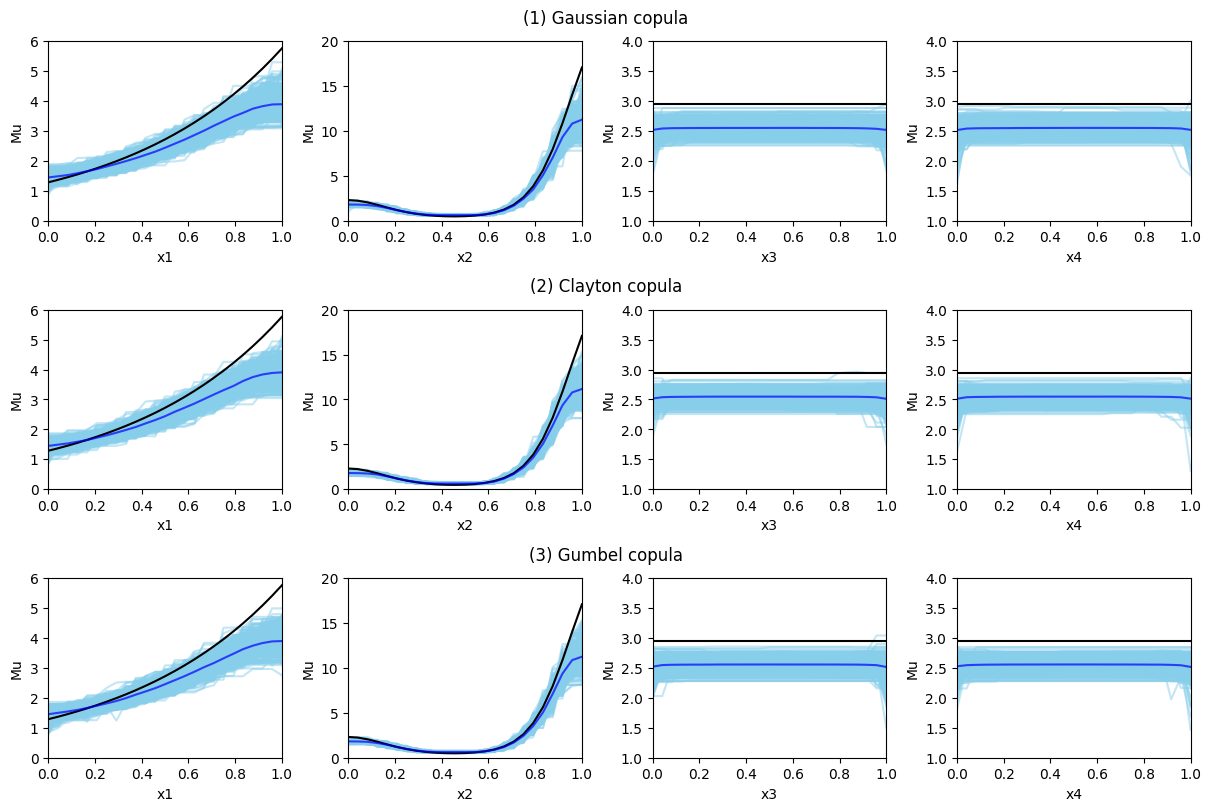

In [31]:
fig = plt.figure(layout='constrained', figsize=(12,8))
subfigs = fig.subfigures(3, 1)

mean_pdp_x1 = [0]*grid_resolution
mean_pdp_x2 = [0]*grid_resolution
mean_pdp_x3 = [0]*grid_resolution
mean_pdp_x4 = [0]*grid_resolution

for i in range(3):
    axs = subfigs[i].subplots(1, 4)
    for j in range(n_sim):
        axs[0].plot(np.linspace(0,1, grid_resolution), results2_linear[copulas[i]][margin]["pdp"]["x1"][j], alpha = 0.5, color="skyblue")
        for k in range(grid_resolution):
            mean_pdp_x1[k] = mean_pdp_x1[k] +  results2_linear[copulas[i]][margin]["pdp"]["x1"][j][k]

    for j in range(len(mean_pdp_x1)):
        mean_pdp_x1[j] = mean_pdp_x1[j]/n_sim
        
    match margin:
        case "lognormal":
            axs[0].plot(np.linspace(0,1, grid_resolution), truth_lognormal_x1, alpha = 1, color="black")
        case "gamma":
            axs[0].plot(np.linspace(0,1, grid_resolution), truth_gamma_x1, alpha = 1, color="black")

    axs[0].plot(np.linspace(0,1, grid_resolution), mean_pdp_x1, alpha=0.7, color="blue")
    axs[0].set_ylim(0, 6)
    axs[0].set_xlim(0, 1)

    for j in range(n_sim):
        axs[1].plot(np.linspace(0,1, grid_resolution), results2_linear[copulas[i]][margin]["pdp"]["x2"][j], alpha = 0.5, color="skyblue")
        for k in range(grid_resolution):
            mean_pdp_x2[k] = mean_pdp_x2[k] +  results2_linear[copulas[i]][margin]["pdp"]["x2"][j][k]

    for j in range(len(mean_pdp_x2)):
        mean_pdp_x2[j] = mean_pdp_x2[j]/n_sim
    
    match margin:
        case "lognormal":
            axs[1].plot(np.linspace(0,1, grid_resolution), truth_lognormal_x2, alpha = 1, color="black")
        case "gamma":
            axs[1].plot(np.linspace(0,1, grid_resolution), truth_gamma_x2, alpha = 1, color="black")
        
    axs[1].plot(np.linspace(0,1, grid_resolution), mean_pdp_x2, alpha=0.7, color="blue")
    axs[1].set_ylim(0, 20)
    axs[1].set_xlim(0, 1)

    for j in range(n_sim):
        axs[2].plot(np.linspace(0,1, grid_resolution), results2_linear[copulas[i]][margin]["pdp"]["x3"][j], alpha = 0.5, color="skyblue")
        for k in range(grid_resolution):
            mean_pdp_x3[k] = mean_pdp_x3[k] +  results2_linear[copulas[i]][margin]["pdp"]["x3"][j][k]

    for j in range(len(mean_pdp_x3)):
        mean_pdp_x3[j] = mean_pdp_x3[j]/n_sim
    
    match margin:
        case "lognormal":
            axs[2].plot(np.linspace(0,1, grid_resolution), truth_lognormal_x3, alpha = 1, color="black")
        case "gamma":
            axs[2].plot(np.linspace(0,1, grid_resolution), truth_gamma_x3, alpha = 1, color="black")
    
    axs[2].plot(np.linspace(0,1, grid_resolution), mean_pdp_x3, alpha=0.7, color="blue")
    axs[2].set_ylim(1, 4)
    axs[2].set_xlim(0, 1)

    for j in range(n_sim):
        axs[3].plot(np.linspace(0,1, grid_resolution), results2_linear[copulas[i]][margin]["pdp"]["x4"][j], alpha = 0.5, color="skyblue")
        for k in range(grid_resolution):
            mean_pdp_x4[k] = mean_pdp_x4[k] +  results2_linear[copulas[i]][margin]["pdp"]["x4"][j][k]

    for j in range(len(mean_pdp_x4)):
        mean_pdp_x4[j] = mean_pdp_x4[j]/n_sim
    
    match margin:
        case "lognormal":
            axs[3].plot(np.linspace(0,1, grid_resolution), truth_lognormal_x4, alpha = 1, color="black")
        case "gamma":
            axs[3].plot(np.linspace(0,1, grid_resolution), truth_gamma_x4, alpha = 1, color="black")

    axs[3].plot(np.linspace(0,1, grid_resolution), mean_pdp_x4, alpha=0.7, color="blue")
    axs[3].set_ylim(1, 4)
    axs[3].set_xlim(0, 1)

    axs[0].set(xlabel='x1', ylabel='Mu')
    axs[1].set(xlabel='x2', ylabel='Mu')
    axs[2].set(xlabel='x3', ylabel='Mu')
    axs[3].set(xlabel='x4', ylabel='Mu')
    subfigs[i].suptitle(f"({i+1}) {Copulas[i]} copula")

#fig.suptitle(f"Estimated covariate effect for {margin} (Linear dependence)")
plt.show()


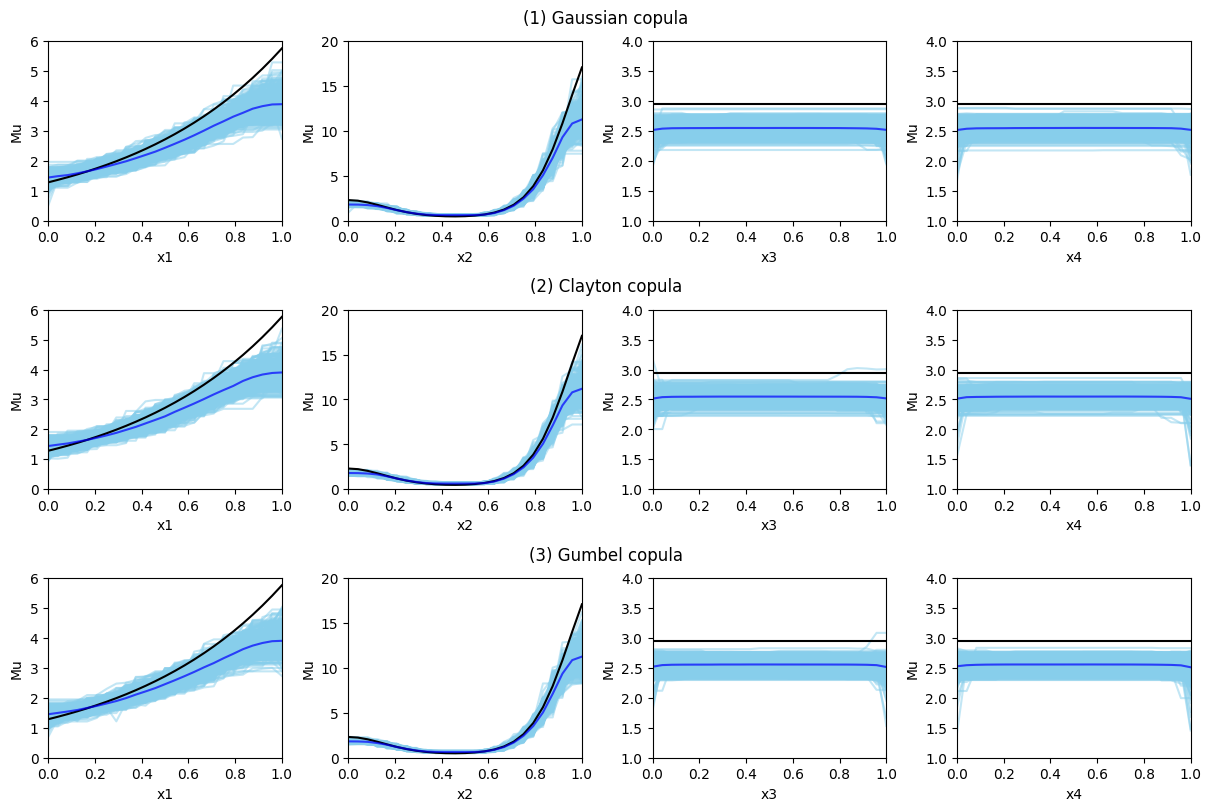

In [32]:
fig = plt.figure(layout='constrained', figsize=(12,8))
subfigs = fig.subfigures(3, 1)

mean_pdp_x1 = [0]*grid_resolution
mean_pdp_x2 = [0]*grid_resolution
mean_pdp_x3 = [0]*grid_resolution
mean_pdp_x4 = [0]*grid_resolution

for i in range(3):
    axs = subfigs[i].subplots(1, 4)
    for j in range(n_sim):
        axs[0].plot(np.linspace(0,1, grid_resolution), results2_nonlinear[copulas[i]][margin]["pdp"]["x1"][j], alpha = 0.5, color="skyblue")
        for k in range(grid_resolution):
            mean_pdp_x1[k] = mean_pdp_x1[k] +  results2_nonlinear[copulas[i]][margin]["pdp"]["x1"][j][k]

    for j in range(len(mean_pdp_x1)):
        mean_pdp_x1[j] = mean_pdp_x1[j]/n_sim
        
    match margin:
        case "lognormal":
            axs[0].plot(np.linspace(0,1, grid_resolution), truth_lognormal_x1, alpha = 1, color="black")
        case "gamma":
            axs[0].plot(np.linspace(0,1, grid_resolution), truth_gamma_x1, alpha = 1, color="black")

    axs[0].plot(np.linspace(0,1, grid_resolution), mean_pdp_x1, alpha=0.7, color="blue")
    axs[0].set_ylim(0, 6)
    axs[0].set_xlim(0, 1)

    for j in range(n_sim):
        axs[1].plot(np.linspace(0,1, grid_resolution), results2_nonlinear[copulas[i]][margin]["pdp"]["x2"][j], alpha = 0.5, color="skyblue")
        for k in range(grid_resolution):
            mean_pdp_x2[k] = mean_pdp_x2[k] +  results2_nonlinear[copulas[i]][margin]["pdp"]["x2"][j][k]

    for j in range(len(mean_pdp_x2)):
        mean_pdp_x2[j] = mean_pdp_x2[j]/n_sim
    
    match margin:
        case "lognormal":
            axs[1].plot(np.linspace(0,1, grid_resolution), truth_lognormal_x2, alpha = 1, color="black")
        case "gamma":
            axs[1].plot(np.linspace(0,1, grid_resolution), truth_gamma_x2, alpha = 1, color="black")
        
    axs[1].plot(np.linspace(0,1, grid_resolution), mean_pdp_x2, alpha=0.7, color="blue")
    axs[1].set_ylim(0, 20)
    axs[1].set_xlim(0, 1)

    for j in range(n_sim):
        axs[2].plot(np.linspace(0,1, grid_resolution), results2_nonlinear[copulas[i]][margin]["pdp"]["x3"][j], alpha = 0.5, color="skyblue")
        for k in range(grid_resolution):
            mean_pdp_x3[k] = mean_pdp_x3[k] +  results2_nonlinear[copulas[i]][margin]["pdp"]["x3"][j][k]

    for j in range(len(mean_pdp_x3)):
        mean_pdp_x3[j] = mean_pdp_x3[j]/n_sim
    
    match margin:
        case "lognormal":
            axs[2].plot(np.linspace(0,1, grid_resolution), truth_lognormal_x3, alpha = 1, color="black")
        case "gamma":
            axs[2].plot(np.linspace(0,1, grid_resolution), truth_gamma_x3, alpha = 1, color="black")
    
    axs[2].plot(np.linspace(0,1, grid_resolution), mean_pdp_x3, alpha=0.7, color="blue")
    axs[2].set_ylim(1, 4)
    axs[2].set_xlim(0, 1)

    for j in range(n_sim):
        axs[3].plot(np.linspace(0,1, grid_resolution), results2_nonlinear[copulas[i]][margin]["pdp"]["x4"][j], alpha = 0.5, color="skyblue")
        for k in range(grid_resolution):
            mean_pdp_x4[k] = mean_pdp_x4[k] +  results2_nonlinear[copulas[i]][margin]["pdp"]["x4"][j][k]

    for j in range(len(mean_pdp_x4)):
        mean_pdp_x4[j] = mean_pdp_x4[j]/n_sim
    
    match margin:
        case "lognormal":
            axs[3].plot(np.linspace(0,1, grid_resolution), truth_lognormal_x4, alpha = 1, color="black")
        case "gamma":
            axs[3].plot(np.linspace(0,1, grid_resolution), truth_gamma_x4, alpha = 1, color="black")

    axs[3].plot(np.linspace(0,1, grid_resolution), mean_pdp_x4, alpha=0.7, color="blue")
    axs[3].set_ylim(1, 4)
    axs[3].set_xlim(0, 1)

    axs[0].set(xlabel='x1', ylabel='Mu')
    axs[1].set(xlabel='x2', ylabel='Mu')
    axs[2].set(xlabel='x3', ylabel='Mu')
    axs[3].set(xlabel='x4', ylabel='Mu')
    subfigs[i].suptitle(f"({i+1}) {Copulas[i]} copula")

#fig.suptitle(f"Estimated covariate effect for {margin} (Non-linear dependence)")
plt.show()


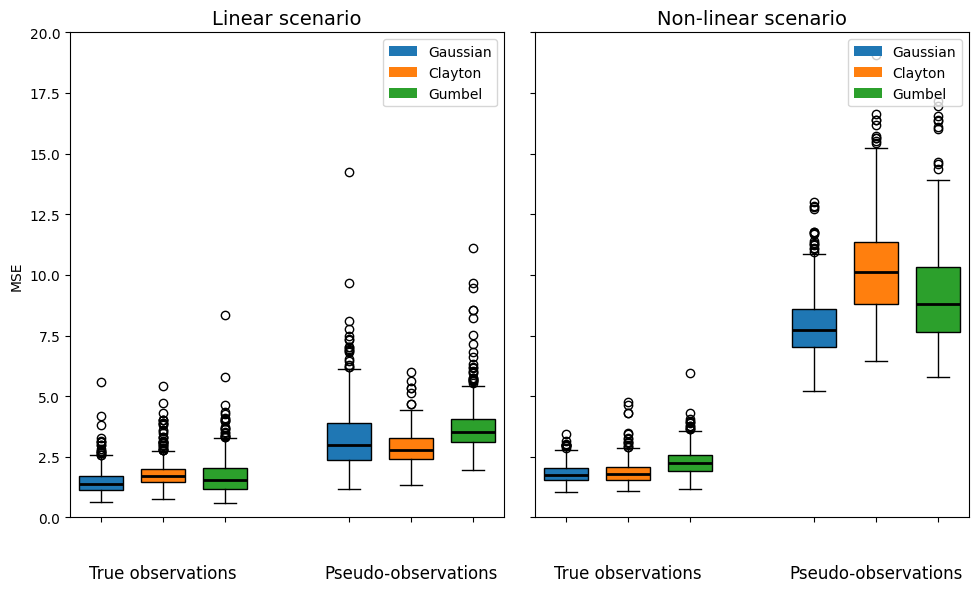

In [42]:
from matplotlib.patches import Patch

# One color per copula
copula_colors = {
    "gaussian": "C0",
    "clayton": "C1",
    "gumbel": "C2"
}

fig, axs = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(10,6),
    sharey=True
)

# =========================================================
# Common positions
# =========================================================

true_positions = [1, 2, 3]
pseudo_positions = [5, 6, 7]

all_positions = true_positions + pseudo_positions

all_labels = []
#all_labels = [
    #"Gaussian",
    #"Clayton",
    #"Gumbel",
    #"Gaussian",
    #"Clayton",
    #"Gumbel"
#]

# =========================================================
# Helper function
# =========================================================

def add_colored_boxplots(ax, data, positions):

    bp = ax.boxplot(
        data,
        positions=positions,
        widths=0.7,
        patch_artist=True,
        medianprops=dict(color="black", linewidth=2)
    )

    # Color each box according to copula
    for patch, cop in zip(bp["boxes"], copulas):
        patch.set_facecolor(copula_colors[cop])

    return bp

# =========================================================
# Linear scenario
# =========================================================

ax = axs[0]

linear_true = [
    results1["linear"][cop]["mse_xgb"]
    for cop in copulas
]

linear_pseudo = [
    results2_linear[cop]["mse_xgb"]
    for cop in copulas
]

# Draw boxplots
add_colored_boxplots(ax, linear_true, true_positions)
add_colored_boxplots(ax, linear_pseudo, pseudo_positions)

# Axis formatting
ax.set_xticks(all_positions)
ax.set_xticklabels(all_labels, rotation=20)

ax.text(2, -2.5, "True observations", ha="center", fontsize=12)
ax.text(6, -2.5, "Pseudo-observations", ha="center", fontsize=12)

ax.set_title("Linear scenario", fontsize=14)
ax.set_ylabel("MSE")
ax.set_ylim(0, 20)

# Legend
legend_handles = [
    Patch(facecolor=copula_colors["gaussian"], label="Gaussian"),
    Patch(facecolor=copula_colors["clayton"], label="Clayton"),
    Patch(facecolor=copula_colors["gumbel"], label="Gumbel")
]

ax.legend(handles=legend_handles, loc="upper right")

# =========================================================
# Non-linear scenario
# =========================================================

ax = axs[1]

nonlinear_true = [
    results1["non-linear"][cop]["mse_xgb"]
    for cop in copulas
]

nonlinear_pseudo = [
    results2_nonlinear[cop]["mse_constant"]
    for cop in copulas
]

# Draw boxplots
add_colored_boxplots(ax, nonlinear_true, true_positions)
add_colored_boxplots(ax, nonlinear_pseudo, pseudo_positions)

# Axis formatting
ax.set_xticks(all_positions)
ax.set_xticklabels(all_labels, rotation=20)

ax.text(2, -2.5, "True observations", ha="center", fontsize=12)
ax.text(6, -2.5, "Pseudo-observations", ha="center", fontsize=12)

ax.set_title("Non-linear scenario", fontsize=14)
ax.set_ylim(0, 20)

# Legend
ax.legend(handles=legend_handles, loc="upper right")

# =========================================================

#fig.suptitle("MSE (model estimates vs true parameter)", fontsize=16)

plt.tight_layout()
plt.show()

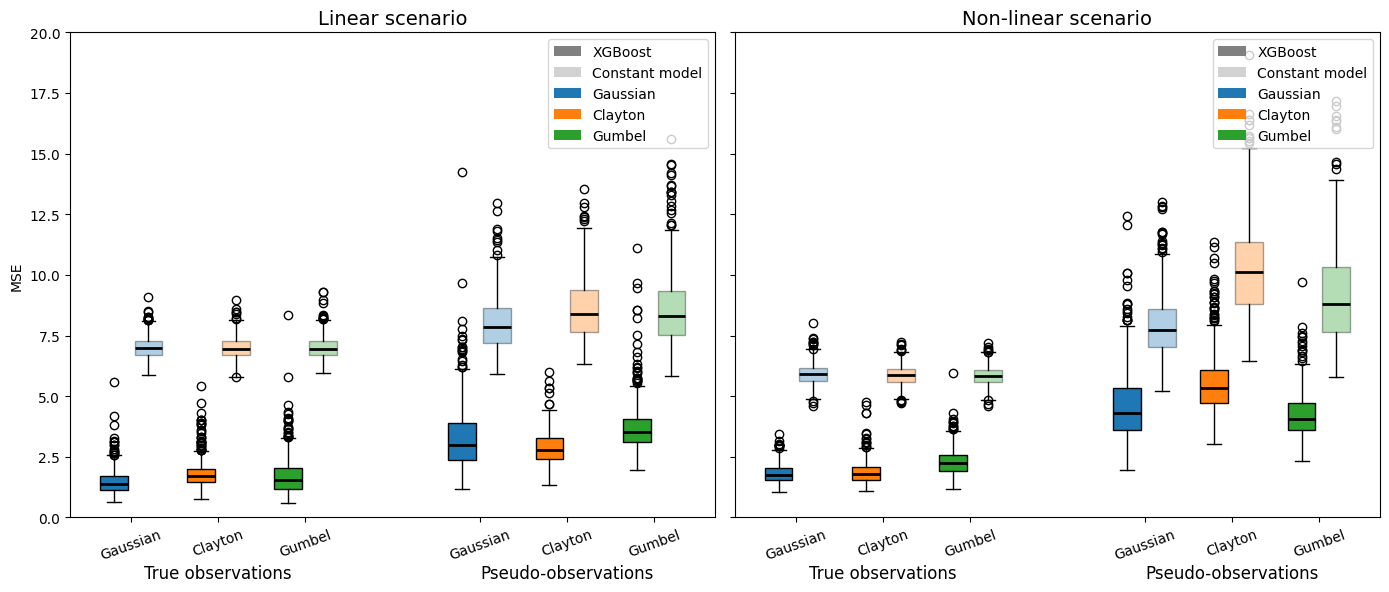

In [69]:
from matplotlib.patches import Patch
import matplotlib.pyplot as plt

# One color per copula
copula_colors = {
    "gaussian": "C0",
    "clayton": "C1",
    "gumbel": "C2"
}

# Colors for model types
xgb_alpha = 1.0
constant_alpha = 0.35

fig, axs = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(14, 6),
    sharey=True
)

# =========================================================
# Common positions
# =========================================================

true_xgb_positions = [1, 2, 3]
true_const_positions = [1.4, 2.4, 3.4]

pseudo_xgb_positions = [5, 6, 7]
pseudo_const_positions = [5.4, 6.4, 7.4]

all_positions = [
    1.2, 2.2, 3.2,
    5.2, 6.2, 7.2
]

#all_labels = [
    #"Gaussian",
    #"Clayton",
    #"Gumbel",
    #"Gaussian",
    #"Clayton",
    #"Gumbel"
#]

# =========================================================
# Helper function
# =========================================================

def add_colored_boxplots(ax, data, positions, copulas, alpha=1.0):

    bp = ax.boxplot(
        data,
        positions=positions,
        widths=0.32,
        patch_artist=True,
        medianprops=dict(color="black", linewidth=2)
    )

    for patch, cop in zip(bp["boxes"], copulas):
        patch.set_facecolor(copula_colors[cop])
        patch.set_alpha(alpha)

    return bp

# =========================================================
# Linear scenario
# =========================================================

ax = axs[0]

# XGBoost
linear_true_xgb = [
    results1["linear"][cop]["mse_xgb"]
    for cop in copulas
]

linear_pseudo_xgb = [
    results2_linear[cop]["mse_xgb"]
    for cop in copulas
]

# Constant model
linear_true_const = [
    results1["linear"][cop]["mse_constant"]
    for cop in copulas
]

linear_pseudo_const = [
    results2_linear[cop]["mse_constant"]
    for cop in copulas
]

# Draw boxplots
add_colored_boxplots(
    ax,
    linear_true_xgb,
    true_xgb_positions,
    copulas,
    alpha=xgb_alpha
)

add_colored_boxplots(
    ax,
    linear_true_const,
    true_const_positions,
    copulas,
    alpha=constant_alpha
)

add_colored_boxplots(
    ax,
    linear_pseudo_xgb,
    pseudo_xgb_positions,
    copulas,
    alpha=xgb_alpha
)

add_colored_boxplots(
    ax,
    linear_pseudo_const,
    pseudo_const_positions,
    copulas,
    alpha=constant_alpha
)

# Axis formatting
ax.set_xticks(all_positions)
ax.set_xticklabels(all_labels, rotation=20)

ax.text(2.2, -2.5, "True observations", ha="center", fontsize=12)
ax.text(6.2, -2.5, "Pseudo-observations", ha="center", fontsize=12)

ax.set_title("Linear scenario", fontsize=14)
ax.set_ylabel("MSE")
ax.set_ylim(0, 20)

# Legend
legend_handles = [
    Patch(facecolor="gray", alpha=xgb_alpha, label="XGBoost"),
    Patch(facecolor="gray", alpha=constant_alpha, label="Constant model"),
    Patch(facecolor=copula_colors["gaussian"], label="Gaussian"),
    Patch(facecolor=copula_colors["clayton"], label="Clayton"),
    Patch(facecolor=copula_colors["gumbel"], label="Gumbel")
]

ax.legend(handles=legend_handles, loc="upper right")

# =========================================================
# Non-linear scenario
# =========================================================

ax = axs[1]

# XGBoost
nonlinear_true_xgb = [
    results1["non-linear"][cop]["mse_xgb"]
    for cop in copulas
]

nonlinear_pseudo_xgb = [
    results2_nonlinear[cop]["mse_xgb"]
    for cop in copulas
]

# Constant model
nonlinear_true_const = [
    results1["non-linear"][cop]["mse_constant"]
    for cop in copulas
]

nonlinear_pseudo_const = [
    results2_nonlinear[cop]["mse_constant"]
    for cop in copulas
]

# Draw boxplots
add_colored_boxplots(
    ax,
    nonlinear_true_xgb,
    true_xgb_positions,
    copulas,
    alpha=xgb_alpha
)

add_colored_boxplots(
    ax,
    nonlinear_true_const,
    true_const_positions,
    copulas,
    alpha=constant_alpha
)

add_colored_boxplots(
    ax,
    nonlinear_pseudo_xgb,
    pseudo_xgb_positions,
    copulas,
    alpha=xgb_alpha
)

add_colored_boxplots(
    ax,
    nonlinear_pseudo_const,
    pseudo_const_positions,
    copulas,
    alpha=constant_alpha
)

# Axis formatting
ax.set_xticks(all_positions)
ax.set_xticklabels(all_labels, rotation=20)

ax.text(2.2, -2.5, "True observations", ha="center", fontsize=12)
ax.text(6.2, -2.5, "Pseudo-observations", ha="center", fontsize=12)

ax.set_title("Non-linear scenario", fontsize=14)
ax.set_ylim(0, 20)

ax.legend(handles=legend_handles, loc="upper right")

# =========================================================

plt.tight_layout()
plt.show()

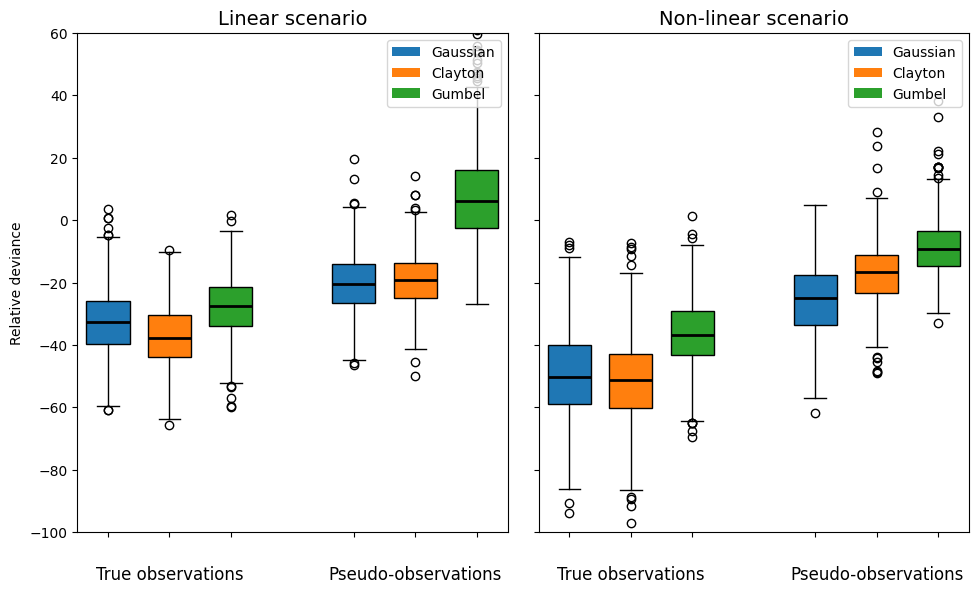

In [39]:
from matplotlib.patches import Patch

# One color per copula
copula_colors = {
    "gaussian": "C0",
    "clayton": "C1",
    "gumbel": "C2"
}

fig, axs = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(10, 6),
    sharey=True
)

# =========================================================
# Common positions
# =========================================================

true_positions = [1, 2, 3]
pseudo_positions = [5, 6, 7]

all_positions = true_positions + pseudo_positions
all_labels = []
# all_labels = [
#     "Gaussian",
#     "Clayton",
#     "Gumbel",
#     "Gaussian",
#     "Clayton",
#     "Gumbel"
# ]

# =========================================================
# Helper function
# =========================================================

def compute_deviance(nll_xgb, nll_constant):
    return -2 * (-np.array(nll_xgb) + np.array(nll_constant))

def add_colored_boxplots(ax, data, positions):

    bp = ax.boxplot(
        data,
        positions=positions,
        widths=0.7,
        patch_artist=True,
        medianprops=dict(color="black", linewidth=2)
    )

    # Color each box according to copula
    for patch, cop in zip(bp["boxes"], copulas):
        patch.set_facecolor(copula_colors[cop])

    return bp

# =========================================================
# Linear scenario
# =========================================================

ax = axs[0]

linear_true = [
    compute_deviance(
        results1["linear"][cop]["nll_xgb"],
        results1["linear"][cop]["nll_constant"]
    )
    for cop in copulas
]

linear_pseudo = [
    compute_deviance(
        results2_linear[cop]["nll_xgb"],
        results2_linear[cop]["nll_constant"]
    )
    for cop in copulas
]

# Draw boxplots
add_colored_boxplots(ax, linear_true, true_positions)
add_colored_boxplots(ax, linear_pseudo, pseudo_positions)

# Formatting
ax.set_xticks(all_positions)
ax.set_xticklabels(all_labels, rotation=20)

ax.text(2, -115, "True observations", ha="center", fontsize=12)
ax.text(6, -115, "Pseudo-observations", ha="center", fontsize=12)

ax.set_title("Linear scenario", fontsize=14)
ax.set_ylabel("Relative deviance")
ax.set_ylim(-100, 60)

# Legend
legend_handles = [
    Patch(facecolor=copula_colors["gaussian"], label="Gaussian"),
    Patch(facecolor=copula_colors["clayton"], label="Clayton"),
    Patch(facecolor=copula_colors["gumbel"], label="Gumbel")
]

ax.legend(handles=legend_handles, loc="upper right")

# =========================================================
# Non-linear scenario
# =========================================================

ax = axs[1]

nonlinear_true = [
    compute_deviance(
        results1["non-linear"][cop]["nll_xgb"],
        results1["non-linear"][cop]["nll_constant"]
    )
    for cop in copulas
]

nonlinear_pseudo = [
    compute_deviance(
        results2_nonlinear[cop]["nll_xgb"],
        results2_nonlinear[cop]["nll_constant"]
    )
    for cop in copulas
]

# Draw boxplots
add_colored_boxplots(ax, nonlinear_true, true_positions)
add_colored_boxplots(ax, nonlinear_pseudo, pseudo_positions)

# Formatting
ax.set_xticks(all_positions)
ax.set_xticklabels(all_labels, rotation=20)

ax.text(2, -115, "True observations", ha="center", fontsize=12)
ax.text(6, -115, "Pseudo-observations", ha="center", fontsize=12)

ax.set_title("Non-linear scenario", fontsize=14)
ax.set_ylim(-100, 60)

# Legend
ax.legend(handles=legend_handles, loc="upper right")

# =========================================================

#fig.suptitle("Relative copula deviance (XGBoost vs Constant)", fontsize=16)

plt.tight_layout()
plt.show()

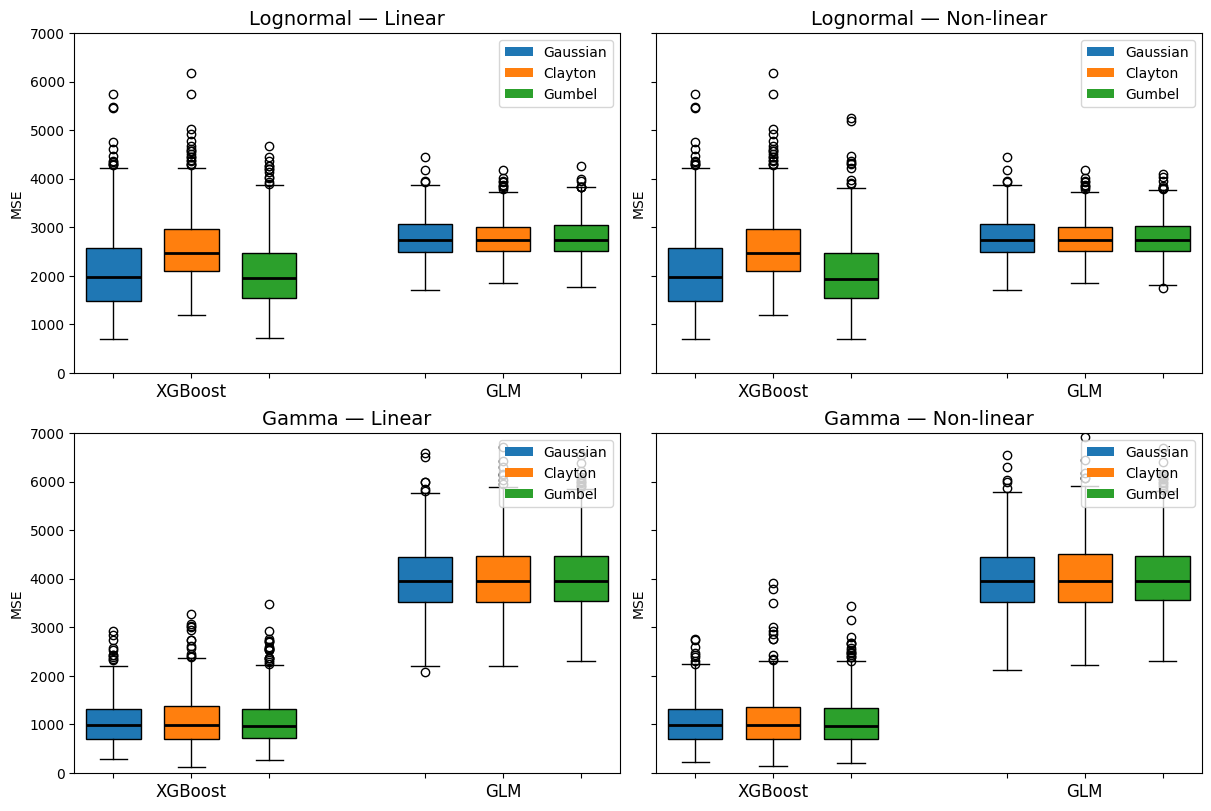

In [38]:
#import matplotlib.pyplot as plt
from matplotlib.patches import Patch

copulas = ["gaussian", "clayton", "gumbel"]
Copulas = ["Gaussian", "Clayton", "Gumbel"]

# One color per copula
copula_colors = {
    "gaussian": "C0",
    "clayton": "C1",
    "gumbel": "C2"
}

# =========================================================
# Figure and subplot layout
# =========================================================

fig, axs = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(12, 8),
    sharey=True,
    layout="constrained"
)

# =========================================================
# Common plotting positions
# =========================================================

xgb_positions = [1, 2, 3]
glm_positions = [5, 6, 7]

all_positions = xgb_positions + glm_positions

all_labels = []

# all_labels = [
#     "Gaussian",
#     "Clayton",
#     "Gumbel",
#     "Gaussian",
#     "Clayton",
#     "Gumbel"
# ]

# =========================================================
# Helper function
# =========================================================

def add_colored_boxplots(ax, data, positions):

    bp = ax.boxplot(
        data,
        positions=positions,
        widths=0.7,
        patch_artist=True,
        medianprops=dict(color="black", linewidth=2)
    )

    # Color by copula
    for patch, cop in zip(bp["boxes"], copulas):
        patch.set_facecolor(copula_colors[cop])

    return bp

# =========================================================
# Legend handles
# =========================================================

legend_handles = [
    Patch(facecolor=copula_colors["gaussian"], label="Gaussian"),
    Patch(facecolor=copula_colors["clayton"], label="Clayton"),
    Patch(facecolor=copula_colors["gumbel"], label="Gumbel")
]

# =========================================================
# Subplot specifications
# =========================================================

subplot_specs = [
    ("lognormal", "linear", axs[0, 0], "Lognormal — Linear"),
    ("lognormal", "non-linear", axs[0, 1], "Lognormal — Non-linear"),
    ("gamma", "linear", axs[1, 0], "Gamma — Linear"),
    ("gamma", "non-linear", axs[1, 1], "Gamma — Non-linear")
]

# =========================================================
# Create all subplots
# =========================================================

for model, scenario, ax, title in subplot_specs:

    # Select appropriate dictionary
    results_dict = (
        results2_linear
        if scenario == "linear"
        else results2_nonlinear
    )

    # XGBoost data
    xgb_data = [
        results_dict[cop][model]["mse_xgb"]
        for cop in copulas
    ]

    # GLM data
    glm_data = [
        results_dict[cop][model]["mse_glm"]
        for cop in copulas
    ]

    # Plot boxplots
    add_colored_boxplots(ax, xgb_data, xgb_positions)
    add_colored_boxplots(ax, glm_data, glm_positions)

    # Axis formatting
    ax.set_xticks(all_positions)
    ax.set_xticklabels(all_labels, rotation=20)

    ax.text(2, -500, "XGBoost", ha="center", fontsize=12)
    ax.text(6, -500, "GLM", ha="center", fontsize=12)

    ax.set_title(title, fontsize=14)
    ax.set_ylabel("MSE")
    ax.set_ylim(0, 7000)

    # Legend
    ax.legend(handles=legend_handles, loc="upper right")

# =========================================================

#fig.suptitle("MSE (model estimates vs true parameter)", fontsize=18)

plt.show()

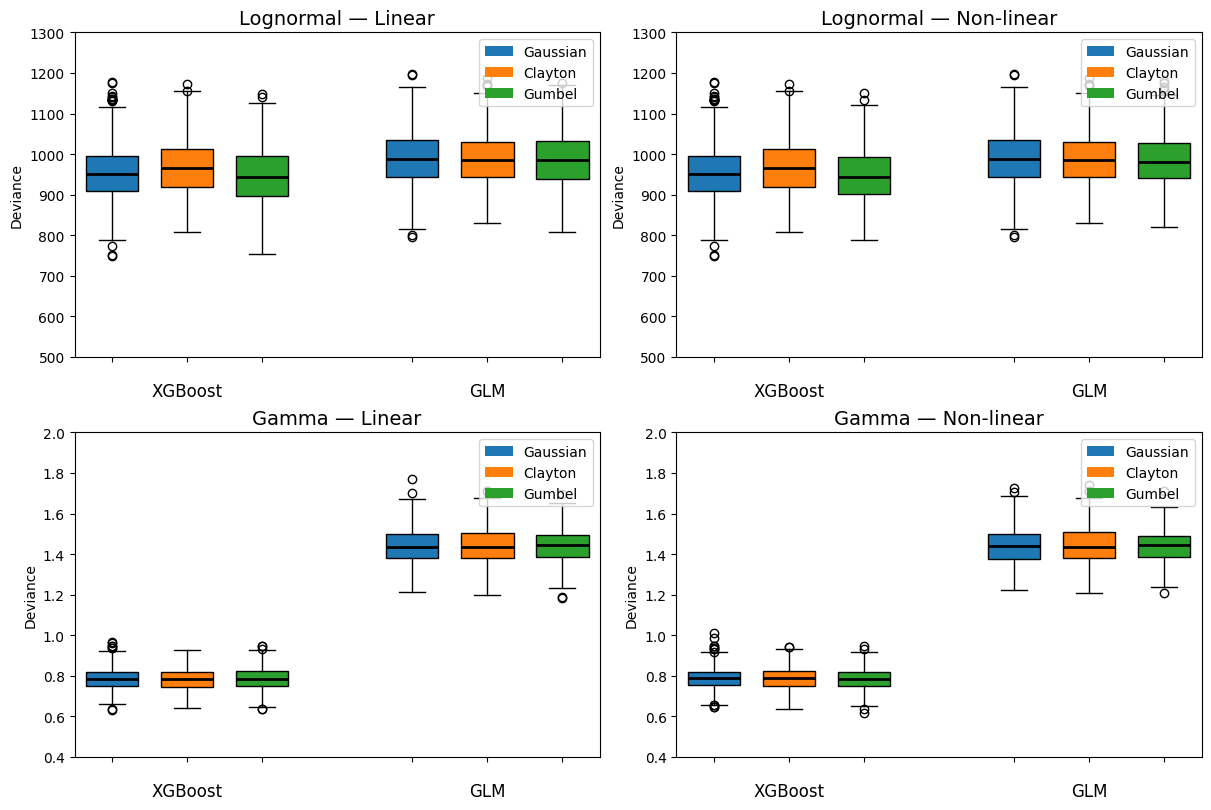

In [40]:
#import matplotlib.pyplot as plt
from matplotlib.patches import Patch

copulas = ["gaussian", "clayton", "gumbel"]
Copulas = ["Gaussian", "Clayton", "Gumbel"]

# One color per copula
copula_colors = {
    "gaussian": "C0",
    "clayton": "C1",
    "gumbel": "C2"
}

# =========================================================
# Figure and subplot layout
# =========================================================

fig, axs = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(12, 8),
    sharey=False,
    layout="constrained"
)

# =========================================================
# Common plotting positions
# =========================================================

xgb_positions = [1, 2, 3]
glm_positions = [5, 6, 7]

all_positions = xgb_positions + glm_positions

all_labels = []
#all_labels = [
    #"Gaussian",
    #"Clayton",
    #"Gumbel",
    #"Gaussian",
    #"Clayton",
    #"Gumbel"
#]

# =========================================================
# Helper function
# =========================================================

def add_colored_boxplots(ax, data, positions):

    bp = ax.boxplot(
        data,
        positions=positions,
        widths=0.7,
        patch_artist=True,
        medianprops=dict(color="black", linewidth=2)
    )

    # Color by copula
    for patch, cop in zip(bp["boxes"], copulas):
        patch.set_facecolor(copula_colors[cop])

    return bp

# =========================================================
# Legend handles
# =========================================================

legend_handles = [
    Patch(facecolor=copula_colors["gaussian"], label="Gaussian"),
    Patch(facecolor=copula_colors["clayton"], label="Clayton"),
    Patch(facecolor=copula_colors["gumbel"], label="Gumbel")
]

# =========================================================
# Subplot specifications
# =========================================================

subplot_specs = [
    ("lognormal", "linear", axs[0, 0], "Lognormal — Linear"),
    ("lognormal", "non-linear", axs[0, 1], "Lognormal — Non-linear"),
    ("gamma", "linear", axs[1, 0], "Gamma — Linear"),
    ("gamma", "non-linear", axs[1, 1], "Gamma — Non-linear")
]

# =========================================================
# Create all subplots
# =========================================================

for model, scenario, ax, title in subplot_specs:

    # Select appropriate dictionary
    results_dict = (
        results2_linear
        if scenario == "linear"
        else results2_nonlinear
    )

    # XGBoost data
    xgb_data = [
        results_dict[cop][model]["deviance_xgb"]
        for cop in copulas
    ]

    # GLM data
    glm_data = [
        results_dict[cop][model]["deviance_glm"]
        for cop in copulas
    ]

    # Plot boxplots
    add_colored_boxplots(ax, xgb_data, xgb_positions)
    add_colored_boxplots(ax, glm_data, glm_positions)

    # Axis formatting
    ax.set_xticks(all_positions)
    ax.set_xticklabels(all_labels, rotation=20)

    #ax.text(2, -500, "XGBoost", ha="center", fontsize=12)
    #ax.text(6, -500, "GLM", ha="center", fontsize=12)
    ax.text(
    2,
    -0.12,
    "XGBoost",
    ha="center",
    fontsize=12,
    transform=ax.get_xaxis_transform()
)

    ax.text(
    6,
    -0.12,
    "GLM",
    ha="center",
    fontsize=12,
    transform=ax.get_xaxis_transform()
)

    ax.set_title(title, fontsize=14)
    ax.set_ylabel("Deviance")

    # Model-specific y-axis limits
    if model == "lognormal":
        ax.set_ylim(500, 1300)
    else:
        ax.set_ylim(0.4, 2)


    # Legend
    ax.legend(handles=legend_handles, loc="upper right")

# =========================================================

#fig.suptitle("Deviance score", fontsize=18)

plt.show()

In [32]:
import os
import sys

# Set project root relative to notebook location
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

from Losses import gaussian_xgb_loss as gauss
from Losses import clayton_xgb_loss as clayton
from Losses import gumbel_xgb_loss as gumbel

def clip_copula_samples(samples, eps=1e-10):
    """
    Ensure copula samples are strictly inside (0, 1)^2.
    
    Parameters:
        samples (np.ndarray): shape (n, 2), values in [0, 1]
        eps (float): small buffer to keep samples strictly in (0, 1)
    
    Returns:
        np.ndarray: clipped samples in (eps, 1 - eps)
    """
    return np.clip(samples, eps, 1 - eps)

seed = 200
tau = 0.7*np.ones((2000,))
eps = 1e-7

u = gauss.sample_gaussian_copula(gauss.gauss_tau2par(tau), seed=seed)
u_clip = clip_copula_samples(u, eps=eps)

print("Gauss")
print(gauss.gaussian_copula_nll_metric(u, gauss.get_initial_guess(u)))
print(gauss.gaussian_copula_nll_metric(u_clip, gauss.get_initial_guess(u_clip)))

u = clayton.sample_clayton_copula(clayton.clayton_tau2par(tau), seed=seed)
u_clip = clip_copula_samples(u, eps=eps)

print("Clayton")
print(clayton.clayton_copula_nll_metric(u, clayton.get_initial_guess(u)))
print(clayton.clayton_copula_nll_metric(u_clip, clayton.get_initial_guess(u_clip)))

u = gumbel.sample_gumbel_copula(gumbel.gumbel_tau2par(tau), seed=seed)
u_clip = clip_copula_samples(u, eps=eps)

print("Gumbel")
print(gumbel.gumbel_copula_nll_metric(u, 0.9))
print(gumbel.gumbel_copula_nll_metric(u_clip, 0.9))

Gauss
-1586.7577794535332
-1586.7577794535332
Clayton
-1864.5853126032787
-1864.5853126032787
Gumbel
-1581.2705653832413
-1581.2705653832413
